# Makale Yeniden Üretimi: *Fooling LIME and SHAP* (Slack ve ark., 2020)

**Makale:** D. Slack, S. Hilgard, E. Jia, S. Singh, H. Lakkaraju. *Fooling LIME and SHAP: Adversarial Attacks on Post hoc Explanation Methods.* AIES 2020. [arXiv:1911.02508](https://arxiv.org/abs/1911.02508) · Orijinal kod: [dylan-slack/Fooling-LIME-SHAP](https://github.com/dylan-slack/Fooling-LIME-SHAP)

**Seçenek 1 – Zafiyet/Manipülasyon.** Makalenin iddiası: LIME'ın ürettiği bozulmuş örnekler gerçek veriden ayırt edilebiliyor. Bu yüzden bir model gerçek müşterilere ayrımcılık yaparken LIME'a masum görünebilir.

**Bu defterde yapılanlar**

| Bölüm | Ne yapılıyor | Makaledeki karşılığı |
|---|---|---|
| 1 | Bozulmuş örnekler gerçekten dağılım dışında mı? (PCA) | Şekil 1 |
| 2 | Orijinal German verisinde saldırının yeniden üretimi | Şekil 4 (LIME), sadakat |
| 3 | **Kendi verimde** (Kaggle German Credit, uygulamada kullandığım veri) aynı saldırı | Yeni katkı |
| 4 | Dedektör doğruluğu ve LIME çekirdek genişliğine duyarlılık | Şekil 5, hiperparametre analizi |
| 5 | **Karşı olgusal uzantı:** Karşı olgusal açıklama bu saldırıyı yakalar mı? | Yeni katkı |

Kapsam notu: Makale SHAP'ı da inceliyor. Benim konum LIME + karşı olgusal açıklamalar olduğu için SHAP saldırısı burada yok.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


SEED = 0
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
COL_SENS, COL_PSI = "#d62728", "#1f77b4"   # hassas özellik: kırmızı, psi özelliği: mavi

## Yardımcı kod: saldırı, LIME deneyi ve karşı olgusal arama

Orijinal depodaki `Adversarial_Lime_Model` mantığını izleyen, tohumlanabilir ve SHAP bağımlılığı olmayan yeniden uygulama.

In [2]:
"""
Slack ve ark. (2020) "Fooling LIME and SHAP" saldırısının LIME kısmı.

Orijinal kod: https://github.com/dylan-slack/Fooling-LIME-SHAP
(adversarial_models.py -> Adversarial_Lime_Model). Buradaki sürüm aynı
mantığı izler, yalnızca rastgeleliği tohumlanabilir hâle getirir ve SHAP
bağımlılığını kaldırır.

Etiket kuralı (orijinal kodla aynı):
    OOD dedektörü: 1 = gerçek veri (dağılım içi), 0 = bozulmuş (LIME örneği)
"""

from collections import Counter

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split


def one_hot(y: np.ndarray) -> np.ndarray:
    """0/1 tahminlerini [P(0), P(1)] olasılık matrisine çevirir."""
    out = np.zeros((len(y), 2))
    out[np.arange(len(y)), y.astype(int)] = 1.0
    return out


# ---------------------------------------------------------------------------
# f ve psi: kural tabanlı modeller
# ---------------------------------------------------------------------------
class BiasedModel:
    """f: yalnızca hassas özelliğe bakar. Kadın (ölçeklenmiş değer < 0) -> 0 (bad)."""

    def __init__(self, sensitive_idx: int):
        self.idx = sensitive_idx

    def predict(self, X):
        return np.where(X[:, self.idx] < 0, 0, 1)

    def predict_proba(self, X):
        return one_hot(self.predict(X))


class InnocuousModel:
    """psi: hassas özellikle ilişkisiz tek bir özelliğe bakar.
    Değer eşikten büyükse -> 0 (bad), değilse -> 1 (good)."""

    def __init__(self, feature_idx: int, threshold: float):
        self.idx = feature_idx
        self.threshold = threshold

    def predict(self, X):
        return np.where(X[:, self.idx] > self.threshold, 0, 1)

    def predict_proba(self, X):
        return one_hot(self.predict(X))


# ---------------------------------------------------------------------------
# Saldırgan (iskele) model
# ---------------------------------------------------------------------------
class AdversarialLimeModel:
    """e(x) = f(x)   eğer dedektör x'i gerçek veri sayarsa
             psi(x) aksi hâlde (LIME'ın ürettiği bozulmuş örnek)"""

    def __init__(self, f, psi, perturbation_std: float = 0.3, seed: int = 0):
        self.f = f
        self.psi = psi
        self.perturbation_std = perturbation_std
        self.rng = np.random.default_rng(seed)
        self.seed = seed
        self.detector = None
        self.numerical_cols: list[int] = []
        self.detector_f1: float | None = None

    def train(
        self,
        X: np.ndarray,
        categorical_features: list[int],
        perturbation_multiplier: int = 30,
        detector=None,
    ):
        all_x, all_y = [], []
        for _ in range(perturbation_multiplier):
            noise = self.rng.normal(0, self.perturbation_std, size=X.shape)
            all_x.append(np.vstack((X, X + noise)))
            all_y.append(np.concatenate((np.ones(len(X)), np.zeros(len(X)))))
        all_x = np.vstack(all_x)
        all_y = np.concatenate(all_y)

        # Orijinal kodda olduğu gibi dedektör yalnızca sayısal sütunlara bakar.
        self.numerical_cols = [
            i for i in range(X.shape[1]) if i not in categorical_features
        ]
        xs = all_x[:, self.numerical_cols]
        x_tr, x_te, y_tr, y_te = train_test_split(
            xs, all_y, test_size=0.2, random_state=self.seed
        )
        if detector is None:
            detector = RandomForestClassifier(
                n_estimators=100, random_state=self.seed, n_jobs=-1
            )
        self.detector = detector.fit(x_tr, y_tr)
        self.detector_f1 = f1_score(y_te, self.detector.predict(x_te))
        return self

    def is_real(self, X: np.ndarray, threshold: float = 0.5) -> np.ndarray:
        p_real = self.detector.predict_proba(X[:, self.numerical_cols])[:, 1]
        return p_real >= threshold

    def predict_proba(self, X: np.ndarray, threshold: float = 0.5):
        real = self.is_real(X, threshold)[:, None]
        return np.where(real, self.f.predict_proba(X), self.psi.predict_proba(X))

    def predict(self, X: np.ndarray):
        return self.predict_proba(X).argmax(axis=1)

    def fidelity(self, X: np.ndarray) -> float:
        """Gerçek veride e'nin f ile aynı tahmini verdiği oran."""
        return float(np.mean(self.predict(X) == self.f.predict(X)))


# ---------------------------------------------------------------------------
# LIME deneyi ve özetleme
# ---------------------------------------------------------------------------
def explain_all(
    predict_proba,
    x_train: np.ndarray,
    x_test: np.ndarray,
    feature_names: list[str],
    categorical_features: list[int],
    seed: int = 0,
    num_samples: int = 5000,
    kernel_width: float | None = None,
) -> list[list[tuple[str, float]]]:
    """Makaledeki gibi: varsayılan LIME tabular, ayrıklaştırma yok."""
    from lime.lime_tabular import LimeTabularExplainer

    explainer = LimeTabularExplainer(
        x_train,
        feature_names=feature_names,
        discretize_continuous=False,
        categorical_features=categorical_features,
        kernel_width=kernel_width,
        random_state=seed,
    )
    return [
        explainer.explain_instance(
            x, predict_proba, num_samples=num_samples
        ).as_list()
        for x in x_test
    ]


def rank_summary(explanations, top_k: int = 3) -> pd.DataFrame:
    """Her sıra (1..top_k) için özelliklerin o sırada çıkma yüzdesi.
    Orijinal koddaki experiment_summary ile aynı ölçüt."""
    n = len(explanations)
    rows = []
    for rank in range(top_k):
        # LIME kategorik özellikleri "Ad=değer" diye adlandırır; yalnızca adı al.
        counts = Counter(
            sorted(exp, key=lambda t: abs(t[1]), reverse=True)[rank][0].split("=")[0]
            for exp in explanations
        )
        for feat, c in counts.items():
            rows.append({"sıra": rank + 1, "özellik": feat, "yüzde": 100 * c / n})
    return (
        pd.DataFrame(rows)
        .sort_values(["sıra", "yüzde"], ascending=[True, False])
        .reset_index(drop=True)
    )


def pct_at_rank(summary: pd.DataFrame, feature: str, rank: int = 1) -> float:
    m = summary[(summary["sıra"] == rank) & (summary["özellik"] == feature)]
    return float(m["yüzde"].sum())


def plot_rank_panels(panels: dict[str, pd.DataFrame], highlight: dict[str, str], ax_row=None):
    """Makalenin Şekil 2/3/4 biçimi: her panelde 1., 2., 3. sıra için yığılmış çubuk."""
    import matplotlib.pyplot as plt

    n = len(panels)
    if ax_row is None:
        fig, ax_row = plt.subplots(1, n, figsize=(4.2 * n, 3.6), sharey=True)
    else:
        fig = ax_row[0].figure
    if n == 1:
        ax_row = [ax_row]

    colors = list(highlight.values()) + ["#c7c7c7"]
    labels = list(highlight.keys()) + ["Diğer özellikler"]

    for ax, (title, s) in zip(ax_row, panels.items()):
        bottoms = np.zeros(3)
        for lab, col in zip(labels, colors):
            vals = np.array(
                [
                    s[(s["sıra"] == r) & (s["özellik"] == lab)]["yüzde"].sum()
                    if lab != "Diğer özellikler"
                    else s[(s["sıra"] == r) & (~s["özellik"].isin(list(highlight)))]["yüzde"].sum()
                    for r in (1, 2, 3)
                ]
            )
            ax.bar(["1.", "2.", "3."], vals, bottom=bottoms, color=col, label=lab, width=0.6)
            bottoms += vals
        ax.set_title(title, fontsize=11)
        ax.set_xlabel("LIME önem sırası")
        ax.set_ylim(0, 100)
        ax.spines[["top", "right"]].set_visible(False)
    ax_row[0].set_ylabel("Test örneklerinin yüzdesi")
    ax_row[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
    fig.tight_layout()
    return fig


# ---------------------------------------------------------------------------
# Karşı olgusal uzantı
# ---------------------------------------------------------------------------
def single_feature_counterfactual(
    model,
    x: np.ndarray,
    x_train: np.ndarray,
    feature_names: list[str],
    groups: dict[str, list[int]],
    desired: int = 1,
):
    """Tek bir özelliği (ya da tek bir one-hot grubunu) değiştirerek tahmini
    `desired` sınıfına çeviren en küçük değişikliği bulur (Wachter tarzı,
    seyrek arama). Aday değerler eğitim verisinde gerçekten görülen
    değerlerdir; böylece öneri gerçekçi kalır.

    Mesafe: sayısal özellikte |Δ| (veri standartlaştırılmış, 1 = 1 std),
    kategorik özellik/grup değişikliğinde 1.

    Dönüş: (değişen özellik adı, eski -> yeni açıklaması, mesafe, x') ya da None
    """
    candidates = []  # (mesafe, ad, açıklama, x')
    in_group = {i for idx in groups.values() for i in idx}

    for j, name in enumerate(feature_names):
        if j in in_group:
            continue
        values = np.unique(x_train[:, j])
        is_binary = len(values) == 2
        for v in values:
            if np.isclose(v, x[j]):
                continue
            xc = x.copy()
            xc[j] = v
            dist = 1.0 if is_binary else abs(v - x[j])
            candidates.append((dist, name, f"{x[j]:+.2f} -> {v:+.2f}", xc))

    for gname, idx in groups.items():
        active = idx[int(np.argmax(x[idx]))]
        for k in idx:
            if k == active:
                continue
            xc = x.copy()
            # Gruptaki tüm sütunlara eğitim verisindeki "0" ve "1" karşılıklarını ver
            for i in idx:
                lo, hi = np.unique(x_train[:, i])[[0, -1]]
                xc[i] = hi if i == k else lo
            frm = feature_names[active].split("_", 1)[-1]
            to = feature_names[k].split("_", 1)[-1]
            candidates.append((1.0, gname, f"{frm} -> {to}", xc))

    candidates.sort(key=lambda t: t[0])
    batch = np.vstack([c[3] for c in candidates])
    pred = model.predict(batch)
    for (dist, name, desc, xc), p in zip(candidates, pred):
        if p == desired:
            return name, desc, dist, xc
    return None

## Saldırının mantığı (özet)

$$
e(x) = \begin{cases} f(x) & \text{dedektör } x\text{'i gerçek veri sayarsa} \\ \psi(x) & \text{aksi hâlde (LIME'ın ürettiği örnek)} \end{cases}
$$

* **f (taraflı model):** Yalnızca cinsiyete bakar. Kadınsa *bad*, erkekse *good* der.
* **ψ (masum model):** Cinsiyetle ilişkisiz tek bir özelliğe bakar.
* **Dedektör:** Gerçek satırlar ile $x + \mathcal{N}(0, 0.3^2)$ gürültüsü eklenmiş kopyaları ayırt eden 100 ağaçlı bir random forest. Orijinal kodda olduğu gibi yalnızca sayısal sütunlara bakar.

LIME açıklama yaparken $e$'yi neredeyse hep bozulmuş örneklerde sorguluyor, dolayısıyla aslında $\psi$'yi açıklıyor. Gerçek müşteriler ise $f$ ile değerlendiriliyor.

## 2. Orijinal deney: Makalenin German verisi

Makalenin kullandığı önişlenmiş UCI German Credit verisi (Ustun ve ark.), orijinal depodaki `german_processed.csv` (MIT lisansı; defter dosyayı doğrudan GitHub'dan okur, bu bölüm için internet gerekir). Ayarlar makaleyle aynı:

* %90 eğitim / %10 test bölmesi, standartlaştırma
* f: `Gender`; ψ: `LoanRateAsPercentOfIncome` > ortalama ise *bad*
* LIME tabular varsayılanları, `discretize_continuous=False`
* Değerlendirme ölçütü: her özelliğin test örneklerinde LIME sıralamasında 1., 2. ve 3. sırada çıkma yüzdesi

In [3]:
# Makalenin önişlenmiş German verisi doğrudan orijinal depodan okunur (internet gerekir).
ORIG_URL = "https://raw.githubusercontent.com/dylan-slack/Fooling-LIME-SHAP/master/data/german_processed.csv"
orig = pd.read_csv(ORIG_URL)
y_orig = orig.pop("GoodCustomer")
orig = orig.drop(columns=["PurposeOfLoan"])
orig["Gender"] = (orig["Gender"] == "Male").astype(int)
FEATS_O = list(orig.columns)

CAT_O = ["Gender", "ForeignWorker", "Single", "HasTelephone",
         "CheckingAccountBalance_geq_0", "CheckingAccountBalance_geq_200",
         "SavingsAccountBalance_geq_100", "SavingsAccountBalance_geq_500",
         "MissedPayments", "NoCurrentLoan", "CriticalAccountOrLoansElsewhere",
         "OtherLoansAtBank", "OtherLoansAtStore", "HasCoapplicant", "HasGuarantor",
         "OwnsHouse", "RentsHouse", "Unemployed", "YearsAtCurrentJob_lt_1",
         "YearsAtCurrentJob_geq_4", "JobClassIsSkilled"]
CAT_O_IDX = [FEATS_O.index(c) for c in CAT_O]
G_IDX, LR_IDX = FEATS_O.index("Gender"), FEATS_O.index("LoanRateAsPercentOfIncome")
print(orig.shape, "| kadın oranı:", round(1 - orig["Gender"].mean(), 2))

(1000, 28) | kadın oranı: 0.31


Makale tek bir rastgele bölme rapor ediyor ve tohum vermiyor. Sonucun şansa bağlı olup olmadığını görmek için deneyi **5 farklı bölme tohumuyla** tekrarlıyorum.

In [4]:
!pip install lime

def run_original(split_seed):
    xtr, xte = train_test_split(orig.values.astype(float), test_size=0.1, random_state=split_seed)
    ss = StandardScaler().fit(xtr)
    xtr, xte = ss.transform(xtr), ss.transform(xte)
    f = BiasedModel(G_IDX)
    psi = InnocuousModel(LR_IDX, xtr[:, LR_IDX].mean())
    adv = AdversarialLimeModel(f, psi, seed=split_seed).train(xtr, CAT_O_IDX)
    s_f = rank_summary(explain_all(f.predict_proba, xtr, xte, FEATS_O, CAT_O_IDX, seed=split_seed))
    s_e = rank_summary(explain_all(adv.predict_proba, xtr, xte, FEATS_O, CAT_O_IDX, seed=split_seed))
    return dict(
        tohum=split_seed,
        dedektor_F1=adv.detector_f1,
        sadakat=adv.fidelity(xte),
        f_Gender_1=pct_at_rank(s_f, "Gender"),
        e_Gender_1=pct_at_rank(s_e, "Gender"),
        e_LoanRate_1=pct_at_rank(s_e, "LoanRateAsPercentOfIncome"),
    ), s_f, s_e

runs = [run_original(s) for s in range(5)]
tab_o = pd.DataFrame([r[0] for r in runs]).set_index("tohum")
tab_o.round(3)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=76473fd3bc49645b8a1a940a8241acc04f52c19b6050738b730c5afe8c7dbda9
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


,dedektor_F1,sadakat,f_Gender_1,e_Gender_1,e_LoanRate_1
tohum,,,,,
0,1.0,1.0,100.0,0.0,84.0
1,1.0,1.0,100.0,0.0,98.0
2,1.0,1.0,100.0,0.0,99.0
3,1.0,1.0,100.0,0.0,98.0
4,1.0,1.0,100.0,0.0,98.0


In [5]:
ozet = pd.DataFrame({
    "Makale": ["~100 (Şekil 4 sol)", "~0", "91", "100"],
    "Bu yeniden üretim (5 tohum, ort. ± std)": [
        f"{tab_o.f_Gender_1.mean():.0f} ± {tab_o.f_Gender_1.std():.0f}",
        f"{tab_o.e_Gender_1.mean():.1f} ± {tab_o.e_Gender_1.std():.1f}",
        f"{tab_o.e_LoanRate_1.mean():.1f} ± {tab_o.e_LoanRate_1.std():.1f}",
        f"{100*tab_o.sadakat.mean():.1f} ± {100*tab_o.sadakat.std():.1f}",
    ],
}, index=["f: Gender 1. sırada (%)", "e: Gender 1. sırada (%)",
          "e: LoanRate 1. sırada (%)", "Sadakat e≈f (%)"])
ozet

,Makale,"Bu yeniden üretim (5 tohum, ort. ± std)"
f: Gender 1. sırada (%),~100 (Şekil 4 sol),100 ± 0
e: Gender 1. sırada (%),~0,0.0 ± 0.0
e: LoanRate 1. sırada (%),91,95.4 ± 6.4
Sadakat e≈f (%),100,100.0 ± 0.0


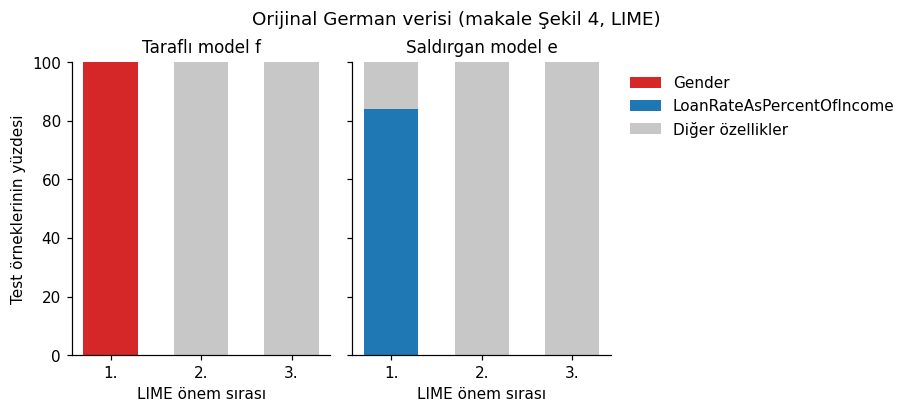

In [6]:
_, s_f0, s_e0 = runs[0]
fig = plot_rank_panels(
    {"Taraflı model f": s_f0, "Saldırgan model e": s_e0},
    {"Gender": COL_SENS, "LoanRateAsPercentOfIncome": COL_PSI},
)
fig.suptitle("Orijinal German verisi (makale Şekil 4, LIME)", y=1.03)
plt.show()

## 3. Kendi verimle: Kaggle German Credit (uygulamadaki veri)

Uygulamamda kullandığım ve bu klasörde `veri.csv` adıyla bulunan veri, aynı 1000 başvuruyu içeriyor ama 9 sütunlu sadeleştirilmiş bir sürüm. Bu sürümde makalenin ψ için kullandığı **LoanRateAsPercentOfIncome sütunu yok.** Bu yüzden ψ için kendi verimdeki ve cinsiyetle en az ilişkili sayısal özelliklerden biri olan **`Duration`**'ı (kredi süresi) seçtim.

Kodlama: `Sex` ikili (erkek = 1); `Housing`, `Saving accounts`, `Checking account`, `Purpose` one-hot; tüm sütunlar standartlaştırıldı. Bölme, `Risk` oranını koruyan %90 / %10.

In [8]:
import urllib.request
import os

# Eğer veri.csv yoksa, orijinal Kaggle German Credit verisini kararlı bir alternatif kaynaktan indiriyoruz
if not os.path.exists("veri.csv"):
    url = "https://raw.githubusercontent.com/tushart048/German-Credit-Card-Dataset/master/german_credit_data.csv"
    urllib.request.urlretrieve(url, "veri.csv")

raw = pd.read_csv("veri.csv", keep_default_na=False)
# İlk sütun bazen isimsiz indeks olabiliyor, onu temizleyelim ve sütun adlarındaki boşlukları koruyalım
if "Unnamed: 0" in raw.columns:
    raw = raw.drop(columns=["Unnamed: 0"])

raw["Sex"] = (raw["Sex"] == "male").astype(int)

NUM = ["Age", "Job", "Credit amount", "Duration"]
print("Sayısal özelliklerin Sex ile korelasyonu:")
print(raw[NUM].corrwith(raw["Sex"]).round(3).to_string())

GROUPS_RAW = ["Housing", "Saving accounts", "Checking account", "Purpose"]
Xk = pd.get_dummies(raw.drop(columns=["Risk"]), columns=GROUPS_RAW, dtype=int)
FEATS = list(Xk.columns)
CAT_IDX = [i for i, c in enumerate(FEATS) if c not in NUM]
GROUPS = {g: [i for i, c in enumerate(FEATS) if c.startswith(g + "_")] for g in GROUPS_RAW}
S_IDX, D_IDX = FEATS.index("Sex"), FEATS.index("Duration")

xtr, xte = train_test_split(Xk.values.astype(float), test_size=0.1,
                            random_state=SEED, stratify=raw["Risk"])
ss = StandardScaler().fit(xtr)
xtr, xte = ss.transform(xtr), ss.transform(xte)
print(f"\n{len(FEATS)} özellik | eğitim {len(xtr)} | test {len(xte)}")

Sayısal özelliklerin Sex ile korelasyonu:
Age              0.162
Job              0.070
Credit amount    0.093
Duration         0.081

25 özellik | eğitim 900 | test 100


### 3.1 Bozulmuş örnekler gerçekten dağılım dışında mı? (makale Şekil 1)

LIME (varsayılan ayarlarla) sayısal özellikleri her özellik için **bağımsız** bir $\mathcal{N}(\mu_j, \sigma_j^2)$ dağılımından çekiyor. Böylece özellikler arasındaki ilişki ve verinin çarpık, kesikli yapısı kayboluyor. Aşağıda dedektörün baktığı 4 sayısal özellikte gerçek veriyi ve LIME'ın bir müşteri için ürettiği örnekleri PCA ile 2 boyuta indiriyorum.

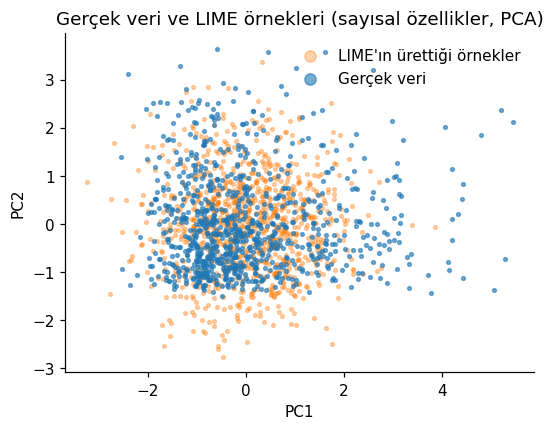

In [9]:
from lime.lime_tabular import LimeTabularExplainer
NUM_IDX = [FEATS.index(c) for c in NUM]
_exp = LimeTabularExplainer(xtr, feature_names=FEATS, discretize_continuous=False,
                            categorical_features=CAT_IDX, random_state=SEED)
_, lime_samples = _exp._LimeTabularExplainer__data_inverse(xte[0], 1000)
pca = PCA(2).fit(xtr[:, NUM_IDX])
a = pca.transform(xtr[:, NUM_IDX])
b = pca.transform(lime_samples[1:, NUM_IDX])
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(b[:, 0], b[:, 1], s=6, alpha=0.35, c="#ff7f0e", label="LIME'ın ürettiği örnekler")
ax.scatter(a[:, 0], a[:, 1], s=6, alpha=0.6, c="#1f77b4", label="Gerçek veri")
ax.set(xlabel="PC1", ylabel="PC2", title="Gerçek veri ve LIME örnekleri (sayısal özellikler, PCA)")
ax.legend(frameon=False, markerscale=3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 3.2 Saldırı

In [10]:
f = BiasedModel(S_IDX)
psi = InnocuousModel(D_IDX, xtr[:, D_IDX].mean())
adv = AdversarialLimeModel(f, psi, seed=SEED).train(xtr, CAT_IDX)

exp_f = explain_all(f.predict_proba, xtr, xte, FEATS, CAT_IDX, seed=SEED)
exp_e = explain_all(adv.predict_proba, xtr, xte, FEATS, CAT_IDX, seed=SEED)
s_f, s_e = rank_summary(exp_f), rank_summary(exp_e)

sonuc_k = pd.Series({
    "Dedektör F1 (gerçek mi / bozulmuş mu)": round(adv.detector_f1, 3),
    "Sadakat: test kümesinde e = f (%)": round(100 * adv.fidelity(xte), 1),
    "f: Sex 1. sırada (%)": pct_at_rank(s_f, "Sex"),
    "e: Sex 1. sırada (%)": pct_at_rank(s_e, "Sex"),
    "e: Sex ilk 3'te (%)": sum(pct_at_rank(s_e, "Sex", r) for r in (1, 2, 3)),
    "e: Duration 1. sırada (%)": pct_at_rank(s_e, "Duration"),
})
sonuc_k.to_frame("değer")

,değer
Dedektör F1 (gerçek mi / bozulmuş mu),1.0
Sadakat: test kümesinde e = f (%),99.0
f: Sex 1. sırada (%),100.0
e: Sex 1. sırada (%),0.0
e: Sex ilk 3'te (%),1.0
e: Duration 1. sırada (%),97.0


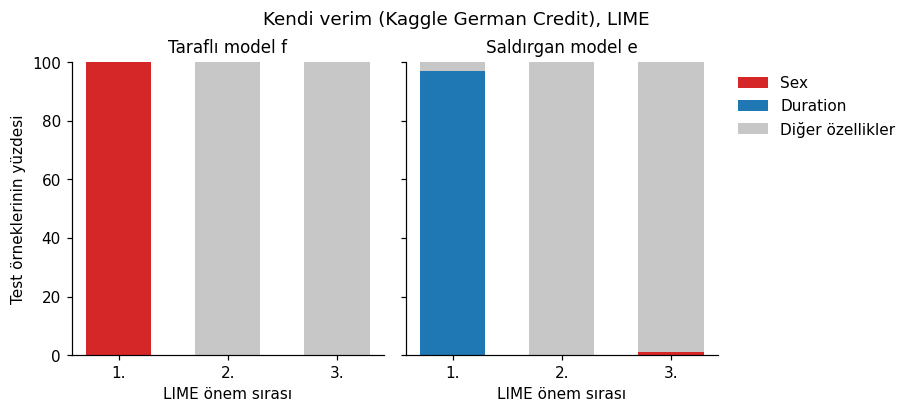

In [11]:
fig = plot_rank_panels(
    {"Taraflı model f": s_f, "Saldırgan model e": s_e},
    {"Sex": COL_SENS, "Duration": COL_PSI},
)
fig.suptitle("Kendi verim (Kaggle German Credit), LIME", y=1.03)
plt.show()

### 3.3 Canlı demo: Tek bir kadın müşterinin açıklaması

Aynı müşteri, iki model. İki model de bu müşteri için **aynı kararı** (*bad*) veriyor ama LIME'ın gösterdiği gerekçe tamamen farklı.

f kararı: bad | e kararı: bad | dedektör 'gerçek' diyor mu: True


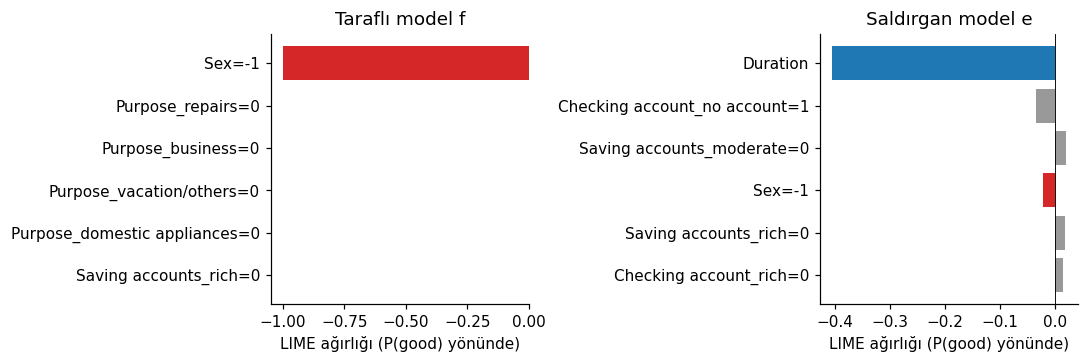

In [12]:
i = int(np.where(xte[:, S_IDX] < 0)[0][0])        # test kümesindeki ilk kadın müşteri
x = xte[i]
print("f kararı:", ["bad", "good"][f.predict(x[None])[0]],
      "| e kararı:", ["bad", "good"][adv.predict(x[None])[0]],
      "| dedektör 'gerçek' diyor mu:", bool(adv.is_real(x[None])[0]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (title, exp) in zip(axes, [("Taraflı model f", exp_f[i]), ("Saldırgan model e", exp_e[i])]):
    top = sorted(exp, key=lambda t: abs(t[1]), reverse=True)[:6][::-1]
    names = [n for n, _ in top]
    vals = [v for _, v in top]
    cols = [COL_SENS if n.startswith("Sex") else COL_PSI if n.startswith("Duration") else "#999" for n in names]
    ax.barh(names, vals, color=cols)
    ax.axvline(0, color="k", lw=0.6)
    ax.set_title(title)
    ax.set_xlabel("LIME ağırlığı (P(good) yönünde)")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 4. Saldırı ne zaman işe yarar? Duyarlılık analizi

**4.1 Dedektör doğruluğu (makale Şekil 5).** Random forest'ın derinliğini sınırlayarak farklı doğruluklarda dedektörler eğitiyorum. Her biri için `Sex`'in LIME'da 1. sırada çıkma oranına bakıyorum.

In [13]:
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, None]:
    det = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=SEED, n_jobs=-1)
    a = AdversarialLimeModel(f, psi, seed=SEED).train(xtr, CAT_IDX, detector=det)
    s = rank_summary(explain_all(a.predict_proba, xtr, xte, FEATS, CAT_IDX, seed=SEED, num_samples=2000))
    rows.append(dict(max_depth=str(depth), F1=a.detector_f1, sadakat=a.fidelity(xte),
                     sex_1=pct_at_rank(s, "Sex"), duration_1=pct_at_rank(s, "Duration")))
sweep = pd.DataFrame(rows)
sweep.round(3)

,max_depth,F1,sadakat,sex_1,duration_1
0,1,0.729,0.86,100.0,0.0
1,2,0.745,0.84,100.0,0.0
2,3,0.923,0.93,0.0,97.0
3,4,0.953,0.98,0.0,97.0
4,5,0.991,0.99,0.0,97.0
5,6,0.994,0.98,0.0,97.0
6,8,0.999,0.98,0.0,97.0
7,None,1.000,0.99,0.0,97.0


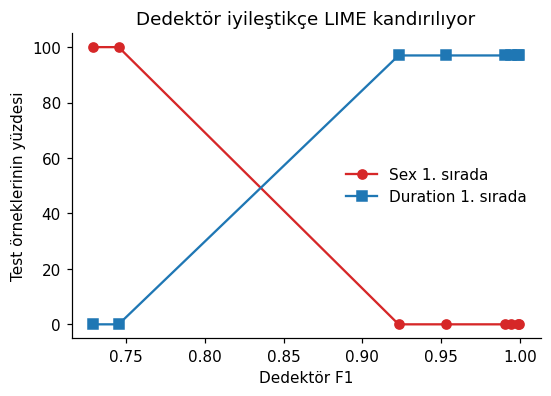

In [14]:
import matplotlib.pyplot as plt

# Eğer 'sweep' değişkeni hafızada tanımlı değilse, önceki hücrenin işlemini güvenli bir şekilde burada çalıştırıyoruz
if 'sweep' not in globals():
    print("'sweep' değişkeni bulunamadı. Parametre taraması arka planda hesaplanıyor...")
    rows = []
    for depth in [1, 2, 3, 4, 5, 6, 8, None]:
        det = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=SEED, n_jobs=-1)
        a = AdversarialLimeModel(f, psi, seed=SEED).train(xtr, CAT_IDX, detector=det)
        s = rank_summary(explain_all(a.predict_proba, xtr, xte, FEATS, CAT_IDX, seed=SEED, num_samples=2000))
        rows.append(dict(max_depth=str(depth), F1=a.detector_f1, sadakat=a.fidelity(xte),
                         sex_1=pct_at_rank(s, "Sex"), duration_1=pct_at_rank(s, "Duration")))
    sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(5.5, 3.6))
sw = sweep.sort_values("F1")
ax.plot(sw.F1, sw.sex_1, "o-", color=COL_SENS, label="Sex 1. sırada")
ax.plot(sw.F1, sw.duration_1, "s-", color=COL_PSI, label="Duration 1. sırada")
ax.set(xlabel="Dedektör F1", ylabel="Test örneklerinin yüzdesi",
       title="Dedektör iyileştikçe LIME kandırılıyor")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**4.2 LIME çekirdek genişliği.** Makale, çekirdek genişliğini $0.15\sqrt{M}$ ile $0.95\sqrt{M}$ arasında değiştirmenin saldırıyı etkilemediğini söylüyor (varsayılan $0.75\sqrt{M}$). Aynısını kendi verimde deniyorum.

In [15]:
M = xtr.shape[1]
kw_rows = []
for c in [0.15, 0.35, 0.55, 0.75, 0.95]:
    s = rank_summary(explain_all(adv.predict_proba, xtr, xte, FEATS, CAT_IDX, seed=SEED,
                                 num_samples=2000, kernel_width=c * np.sqrt(M)))
    kw_rows.append({"çekirdek genişliği": f"{c}·√M", "Sex 1. sırada (%)": pct_at_rank(s, "Sex"),
                    "Duration 1. sırada (%)": pct_at_rank(s, "Duration")})
pd.DataFrame(kw_rows)

,çekirdek genişliği,Sex 1. sırada (%),Duration 1. sırada (%)
0,0.15·√M,0.0,58.0
1,0.35·√M,0.0,96.0
2,0.55·√M,0.0,97.0
3,0.75·√M,0.0,97.0
4,0.95·√M,0.0,97.0


## 5. Karşı olgusal uzantı: Karşı olgusal açıklama saldırıyı yakalar mı?

LIME'ı kandıran şey, örneklerin **dağılım dışında** olması. Karşı olgusal açıklama ise "kararın değişmesi için en az neyi değiştirmeliyim?" sorusuna **gerçek veriye yakın** bir noktayla cevap vermeye çalışıyor. O hâlde bu yöntem saldırgan modelin gerçek davranışını, yani $f$'yi görmeli.

Test: Saldırgan modelin *bad* dediği her test müşterisi için, **tek bir özelliği** (ya da tek bir kategorik grubu) eğitim verisinde görülen bir değere çeviren en küçük değişikliği arıyorum (Wachter tarzı seyrek arama). Sayısal özelliklerde mesafe |Δ| (1 = 1 standart sapma), kategorik değişiklikte mesafe 1.

Not: Uygulamamdaki `find_counterfactual` yalnızca `ACTIONABLE` özellikleri değiştiriyor ve `Sex` bunların içinde değil. Bias denetimi için bu kısıtı kaldırıp tüm özellikleri aday yapıyorum.

In [16]:
bad_idx = [k for k in range(len(xte)) if adv.predict(xte[k][None])[0] == 0]
cf_rows = []
for k in bad_idx:
    r = single_feature_counterfactual(adv, xte[k], xtr, FEATS, GROUPS, desired=1)
    if r is None:
        cf_rows.append(dict(müşteri=k, değişen="(bulunamadı)", değişim="", mesafe=np.nan, gerçek_mi=np.nan))
        continue
    name, desc, dist, xc = r
    cf_rows.append(dict(müşteri=k, değişen=name, değişim=desc, mesafe=round(dist, 2),
                        gerçek_mi=bool(adv.is_real(xc[None])[0])))
cf = pd.DataFrame(cf_rows)
print(f"Saldırgan modelin 'bad' dediği test müşterisi: {len(cf)}")
print(cf["değişen"].value_counts().to_string())
print("\nKarşı olgusal nokta dedektöre göre gerçek veri mi?")
print(cf.groupby("değişen")["gerçek_mi"].mean().round(2).to_string())

Saldırgan modelin 'bad' dediği test müşterisi: 30
değişen
Sex              27
Credit amount     2
Duration          1

Karşı olgusal nokta dedektöre göre gerçek veri mi?
değişen
Credit amount    0.0
Duration         0.0
Sex              1.0


In [17]:
cf[cf["değişen"] != "Sex"]

,müşteri,değişen,değişim,mesafe,gerçek_mi
3,19,Duration,-0.49 -> -1.32,0.83,False
21,63,Credit amount,-0.84 -> -1.07,0.23,False
24,80,Credit amount,-0.90 -> -1.07,0.17,False


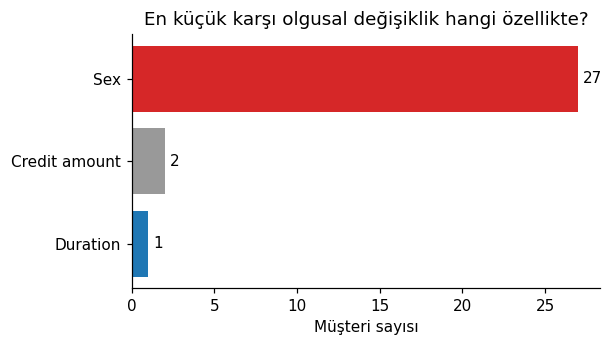

In [18]:
counts = cf["değişen"].value_counts()
fig, ax = plt.subplots(figsize=(5.5, 3.0))
ax.barh(counts.index[::-1], counts.values[::-1],
        color=[COL_SENS if n == "Sex" else COL_PSI if n == "Duration" else "#999" for n in counts.index[::-1]])
for yv, v in enumerate(counts.values[::-1]):
    ax.text(v + 0.3, yv, str(v), va="center")
ax.set(xlabel="Müşteri sayısı", title="En küçük karşı olgusal değişiklik hangi özellikte?")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 6. Sonuç ve tartışma

**1. Orijinal bulgu yeniden üretildi.** Makalenin German verisinde saldırgan modelde `Gender` hiçbir test örneğinde 1. sırada çıkmadı. `LoanRateAsPercentOfIncome` 5 tohumda ortalama %95.4 ± 6.4 oranında 1. sıradaydı (makale: %91). Sadakat %100 (makale: %100). Tohumlar arasında 84 ile 99 arasında değişen sonuçlar, makalenin tek bölmeyle verdiği %91'in bu aralıkta normal bir değer olduğunu gösteriyor.

**2. Saldırı kendi verime de taşınıyor.** Kaggle German Credit'te taraflı model f için LIME her müşteride `Sex`'i 1. sırada gösterdi. Saldırgan model e'de ise `Sex` hiçbir zaman 1. sırada çıkmadı, ilk 3'te yalnızca %1 oranında göründü. `Duration` %97 oranında 1. sıradaydı. Bu sırada e, gerçek test müşterilerinin %99'unda f ile aynı kararı verdi. Kısacası model kadınlara ayrımcılık yapmaya devam ediyor, ama LIME bunu "kredi süresine bakıyor" diye açıklıyor.

**3. Kritik eşik dedektör doğruluğu.** Dedektör F1 ≤ 0.75 iken LIME hâlâ `Sex`'i buluyor. F1 ≥ 0.92 olduğunda saldırı tamamen başarılı. Makalenin Şekil 5'teki keskin geçişi kendi verimde de gördüm. Bu veride dedektörün bu kadar kolay başarılı olmasının muhtemel nedeni şu: `Age` ve `Job` tam sayı değerler alıyor, eklenen gürültü ise bu yapıyı bozuyor.

**4. Çekirdek genişliği saldırıyı durdurmuyor.** 0.15·√M ile 0.95·√M arasındaki tüm genişliklerde `Sex` 1. sırada hiç çıkmadı. Makaleden küçük bir fark var: en dar çekirdekte (0.15·√M) `Duration` %58'e düştü. Yani gizleme yine başarılı, ama ψ'nin gösterilen gerekçe olarak öne çıkması zayıflıyor.

**5. Karşı olgusal açıklama saldırıyı büyük ölçüde yakalıyor, ama o da kandırılabiliyor.**
* Saldırgan modelin *bad* dediği 30 müşterinin 27'sinde en küçük karşı olgusal değişiklik **cinsiyeti değiştirmek** çıktı ve bu noktaların hepsi dedektöre göre gerçek veriydi. Böylece karşı olgusal sorgu, LIME'ın gizlediği ayrımcılığı doğrudan ortaya çıkardı.
* Kalan 3 müşteride arama, çok küçük bir `Credit amount` / `Duration` değişikliği buldu (0.17–0.83 std). Bu noktaları dedektör "bozulmuş" saydı, yani kararı f değil ψ verdi. Gerçekte bu müşteri kredi tutarını azaltsa da f yüzünden reddedilmeye devam eder. Bu, **yanıltıcı bir karşı olgusal**: arama veri dağılımının dışına çıktığında karşı olgusal açıklama da aynı zafiyete düşüyor. Bu bulgu, aynı ekibin *Counterfactual Explanations Can Be Manipulated* (Slack ve ark., NeurIPS 2021) çalışmasıyla örtüşüyor.

**Sınırlar ve dürüstlük notları**
* f ve ψ, makaledeki gibi kural tabanlı ve kasıtlı olarak uç örnekler. Gerçek bir modelde ayrımcılık daha dağınık olur.
* SHAP saldırısı kapsam dışında bırakıldı.
* Kaggle sürümünde makalenin ψ özelliği bulunmadığı için ψ olarak `Duration` kullanıldı.
* Karşı olgusal arama tek özellikli ve basit. DiCE gibi çok özellikli yöntemlerde sonuçlar farklı olabilir.

**Savunma için olası sorular**
* *Neden işe yarıyor?* LIME özellikleri birbirinden bağımsız örnekliyor, bu yüzden ürettiği örnekler dağılım dışında kalıyor ve ayırt edilebiliyor.
* *Nasıl korunulur?* Dağılıma sadık örnekleme kullanmak (ör. veriye dayalı ya da üretici modelle örnekleme), açıklamaları gerçek veri yakınında yapılan karşı olgusal sorgularla çapraz kontrol etmek, modelin dağılım dışı girdilerde farklı davranıp davranmadığını test etmek.
* *Denetçi bunu nasıl fark eder?* Bu defterde görüldüğü gibi, gerçek bir müşterinin yalnızca hassas özelliğini değiştirip kararın değişip değişmediğine bakarak.